<a href="https://colab.research.google.com/github/ptyark/CyberTech-Rekrutacja-Klasyfikacja-mieci/blob/main/lab03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 3 — Sieć neuronowa w NumPy: pętla uczenia i przeuczenie

**Blok I — Podstawy, narzędzia i produkcja** · Lab 3/5 · wykłady 3–4

W Laboratorium 2 zbudowałeś(aś) pojedyncze klocki: warstwy z propagacją w przód i wsteczną, funkcję straty oraz krok
metody gradientu prostego. Tu składamy z nich sieć i uczymy ją na prawdziwych danych. Najpierw dane: skąd się biorą,
jak je dzielimy i dlaczego standaryzujemy. Potem pętla uczenia: najprostsza możliwa (cały zbiór, jeden krok na iterację),
a następnie taka, jakiej używa się w praktyce — mini-paczki, epoki i zbiór walidacyjny. Na końcu to, co pętla uczenia
potrafi zepsuć — przeuczenie — i dwa sposoby, żeby je ograniczyć: wczesne zatrzymanie i dropout.

## Cele

Po tym laboratorium:

- wyjaśnisz, do czego służą zbiory treningowy, walidacyjny i testowy,
- wyjaśnisz, co robi standaryzacja cech i dlaczego jej statystyki liczy się tylko na zbiorze treningowym,
- napiszesz trzy funkcje kroku uczenia (propagacja w przód, propagacja wsteczna, krok optymalizacji) i złożysz z nich pętlę uczenia,
- wyjaśnisz, co do tej pętli dodają mini-paczki, epoki i pomiar dokładności walidacyjnej,
- rozpoznasz przeuczenie i niedouczenie po krzywych uczenia,
- zaimplementujesz wczesne zatrzymanie i dropout i sprawdzisz, co robią z przeuczoną siecią.

## Spis treści

| sekcja | zakres | zadanie |
|---|---|---|
| 1. Dane | wczytanie i podział na część treningową, walidacyjną i testową; standaryzacja; standaryzacja a normalizacja | — |
| 2. Sieć i pętla uczenia | klocki z Laboratorium 2; trzy funkcje kroku uczenia: `forward` → strata → `backward` → `optimizer_step`; złożenie pętli; mini-paczki, epoki, walidacja; logowanie metryk | Zadania 1 i 2 |
| 3. Przeuczenie i niedouczenie | krzywe uczenia na 100 przykładach, luka uogólnienia, sieć za słaba | — |
| 4. Wczesne zatrzymanie i dropout | dwa sposoby na przeuczenie; ocena końcowa na zbiorze testowym i macierz pomyłek | Zadanie 3 |

## Jak pracować z notatnikiem

- Komórki oznaczone **Zadanie N** zawierają `raise NotImplementedError` — zastąp go własnym kodem.
- Bezpośrednio pod każdym zadaniem znajduje się komórka **sprawdzająca** (`assert`). Jeśli wykona się bez błędu, zadanie jest zaliczone.
- **Punktacja:** trzy zadania, **po 1 pkt** każde, łącznie 3 pkt.
- Nazwy zmiennych i funkcji po angielsku; komentarze, docstringi i komunikaty po polsku.
- Notatnik działa w Google Colab i lokalnie; wymaga `numpy` i `matplotlib`. Zbiór danych to plik `data/pumpkin_seeds.csv` (ok. 0,5 MB) obok notatnika; gdy go nie ma (Colab), komórka danych pobiera go sama.
- Komórki uczące sieć działają na CPU, bez GPU. Uruchamiaj je po kolei: późniejsze sekcje korzystają z wyników wcześniejszych.


## 0. Import i ustawienia

| biblioteka | zastosowanie |
|---|---|
| [`numpy`](https://numpy.org/doc/stable/) | sieć i uczenie |
| [`matplotlib.pyplot`](https://matplotlib.org/stable/api/pyplot_summary.html) | krzywe uczenia |
| `pathlib.Path` | ścieżka do pliku z danymi |
| `time.perf_counter` | pomiar czasu epoki i kroku |

| ustawienie | wartość | działanie |
|---|---|---|
| `np.set_printoptions(precision=)` | `4` | cztery miejsca po przecinku w wydrukach |
| `np.set_printoptions(suppress=)` | `True` | bez notacji wykładniczej |
| `rng = np.random.default_rng(42)` | seed `42` | generator do podziału danych; wagi sieci dostają własny seed w argumencie `seed` |


In [ ]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
print("numpy", np.__version__)

numpy 2.1.3


## 1. Dane

### 1.1 Wczytanie i podział

**Pumpkin Seeds** ([Koklu, Sarigil, Özbek, 2021](https://doi.org/10.1007/s10722-021-01226-0)) to 2 500 nasion dyni
dwóch odmian uprawianych w Turcji: *Çerçevelik* (1 300 nasion) i *Ürgüp Sivrisi* (1 200). Każde ziarno sfotografowano,
a z obrazu wyznaczono 12 cech kształtu: pole, obwód, długości osi, pole otoczki wypukłej, średnicę zastępczą, mimośród,
wypukłość, rozciągłość, okrągłość, proporcje osi i zwartość. Pytanie jest binarne, jak w Lab 2: **czy to ziarno odmiany
Çerçevelik?** Klasy są niemal zrównoważone, a zbiór jest mały — 2 500 przykładów to niewiele dla sieci o kilku tysiącach
parametrów (sekcja 3), więc zobaczymy, jak taka sieć zaczyna zapamiętywać zamiast się uczyć.

Cechy (kolejność jak w pliku; wszystkie wyznaczone z czarno-białego obrazu ziarna, długości i pola w pikselach):

| cecha | znaczenie |
|---|---|
| `Area` | pole ziarna: liczba pikseli |
| `Perimeter` | obwód: długość konturu |
| `Major_Axis_Length`, `Minor_Axis_Length` | długości osi wielkiej i małej elipsy dopasowanej do ziarna |
| `Convex_Area` | pole otoczki wypukłej (najmniejszego wypukłego wielokąta zawierającego ziarno) |
| `Equiv_Diameter` | średnica koła o tym samym polu co ziarno: $\sqrt{4 \cdot \text{Area} / \pi}$ |
| `Eccentricity` | mimośród dopasowanej elipsy: 0 dla koła, bliski 1 dla ziarna bardzo wydłużonego |
| `Solidity` | `Area / Convex_Area`: jak wypukły jest kształt (1 = brak wklęsłości) |
| `Extent` | `Area` / pole prostokąta opisanego na ziarnie |
| `Roundness` | $4\pi \cdot \text{Area} / \text{Perimeter}^2$: 1 dla koła, mniej dla kształtów wydłużonych lub postrzępionych |
| `Aspect_Ration` | stosunek osi wielkiej do małej (w pliku z literówką w nazwie, jak u autorów) |
| `Compactness` | `Equiv_Diameter / Major_Axis_Length`: zwartość, bliska 1 dla kształtów okrągłych |

Pierwsze sześć cech to rozmiary (zależą od wielkości ziarna i rozdzielczości zdjęcia), ostatnie sześć to bezwymiarowe
miary kształtu. W notatniku przykład to wektor 12 liczb, a etykieta `y` to 0 albo 1.

Z całego zbioru losujemy 1 500 przykładów jako **zbiór treningowy** (*training set*; w Lab 2 nazywany zbiorem uczącym),
500 jako **zbiór walidacyjny** (*validation set*), a kolejne 500 to **zbiór testowy** (*test set*). Każdy ma inną rolę:

| zbiór | do czego służy | jak często go używamy |
|---|---|---|
| treningowy | liczymy na nim gradient i robimy kroki optymalizacji | w każdym kroku |
| walidacyjny | mierzymy na nim dokładność (*accuracy*, odsetek trafionych klas) po każdym przejściu przez zbiór treningowy; na jego podstawie dobieramy hiperparametry i decydujemy, kiedy przestać | regularnie w trakcie uczenia |
| testowy | ocena końcowa gotowego modelu | raz, na końcu |

Dokładność na zbiorze treningowym nie jest miarą jakości modelu: sieć może przykłady treningowe zapamiętać (sekcja 3).
Dlatego mierzy się ją na danych, których sieć nie widziała w uczeniu — na zbiorze walidacyjnym. Zbioru walidacyjnego
używa się też, i to często, do **wyboru hiperparametrów** (*hyperparameter tuning*): uczy się kilka wariantów sieci —
z różnym `lr`, liczbą neuronów, rozmiarem mini-paczki, siłą regularyzacji — i zostawia ten z najwyższą dokładnością
walidacyjną; tak samo wybiera się liczbę epok (sekcja 4). Każda taka decyzja dopasowuje jednak model do zbioru
walidacyjnego i zawyża jego wynik. Zbiór testowy nie bierze udziału w żadnej decyzji, więc jako jedyny daje
nieobciążoną ocenę; używa się go raz, po zakończeniu wszystkich wyborów.


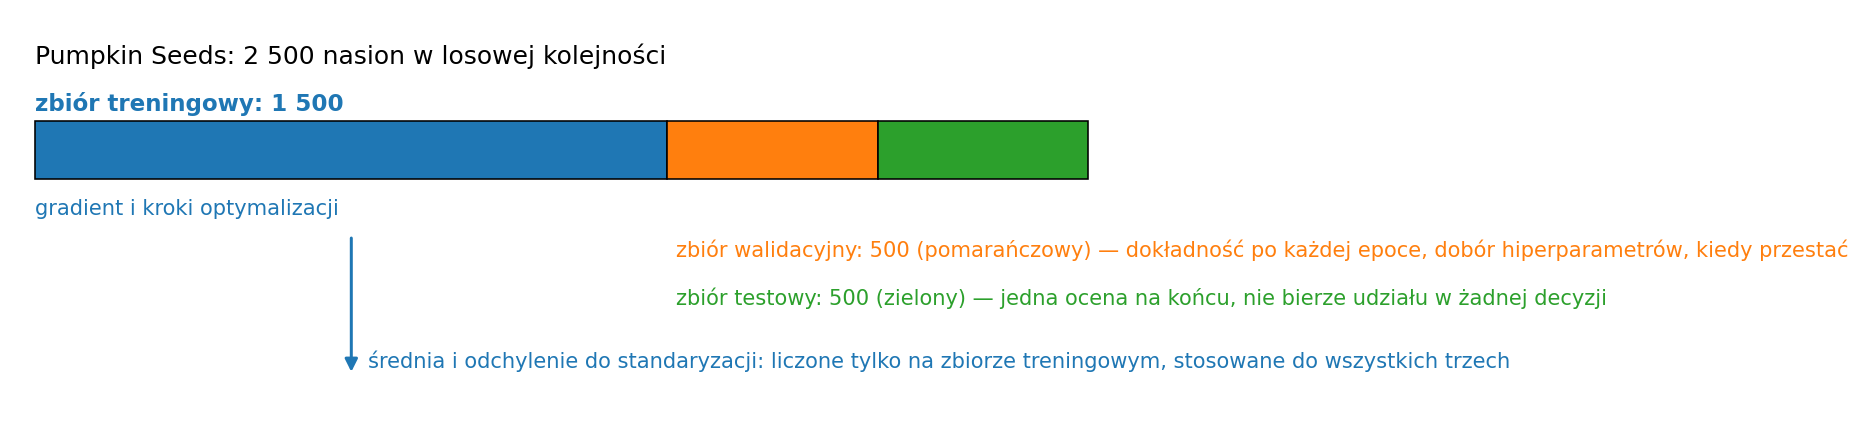

*Podział zbioru: 1 500 przykładów treningowych, 500 walidacyjnych, 500 testowych.*


In [ ]:
N_TRAIN, N_VAL, N_TEST = 1500, 500, 500
DATA_PATH = Path("data/pumpkin_seeds.csv")
if not DATA_PATH.exists():  # np. w Google Colab: pobranie oryginalnego arkusza (ok. 0,3 MB) i zapis jako CSV
    import pandas as pd

    DATA_PATH.parent.mkdir(exist_ok=True)
    pd.read_excel("https://raw.githubusercontent.com/Jonathan-Monir/Pumpkin_Seeds_Dataset/HEAD/Pumpkin_Seeds_Dataset.xlsx").to_csv(
        DATA_PATH, index=False
    )

feature_names = DATA_PATH.read_text(encoding="utf-8").splitlines()[0].split(",")[:-1]
X_all = np.genfromtxt(DATA_PATH, delimiter=",", skip_header=1, usecols=range(12), encoding="utf-8")  # (2500, 12): cechy kształtu
labels = np.genfromtxt(DATA_PATH, delimiter=",", skip_header=1, usecols=[12], dtype=str, encoding="utf-8")  # nazwa odmiany
y_all = (labels == "Çerçevelik").astype(float)[:, None]  # (2500, 1): 1 = Çerçevelik, 0 = Ürgüp Sivrisi

idx = rng.permutation(len(X_all))  # losowa kolejność, potem trzy kolejne kawałki
X_train, y_train = X_all[idx[:N_TRAIN]], y_all[idx[:N_TRAIN]]
X_val, y_val = X_all[idx[N_TRAIN : N_TRAIN + N_VAL]], y_all[idx[N_TRAIN : N_TRAIN + N_VAL]]
X_test, y_test = X_all[idx[N_TRAIN + N_VAL :]], y_all[idx[N_TRAIN + N_VAL :]]

print(f"""X_train  {X_train.shape}   y_train  {y_train.shape}   udział klasy 1: {y_train.mean():.3f}
X_val    {X_val.shape}    y_val    {y_val.shape}
X_test   {X_test.shape}    y_test   {y_test.shape}
""")
print(f"{'cecha':20s} {'min':>10s} {'max':>10s} {'średnia':>10s} {'odch.':>10s}")
for j in [0, 1, 6, 7, 11]:  # kilka cech o bardzo różnych skalach
    col = X_train[:, j]
    print(f"{feature_names[j]:20s} {col.min():10.3f} {col.max():10.3f} {col.mean():10.3f} {col.std():10.3f}")

X_train  (1500, 12)   y_train  (1500, 1)   udział klasy 1: 0.523
X_val    (500, 12)    y_val    (500, 1)
X_test   (500, 12)    y_test   (500, 1)

cecha                       min        max    średnia      odch.
Area                  47939.000 136574.000  81088.047  13692.890
Perimeter               868.485   1559.450   1134.540    110.185
Eccentricity              0.688      0.946      0.862      0.045
Solidity                  0.954      0.994      0.989      0.003
Compactness               0.567      0.849      0.703      0.053


### 1.2 Standaryzacja

**Co widać w wydruku.** Pole ziarna to liczby od 48 000 do 137 000 (pikseli), obwód — od 870 do 1 560, mimośród
i zwartość to ułamki między 0,5 a 1, a wypukłość (*solidity*) prawie zawsze wynosi 0,99 i różni się między ziarnami
o tysięczne. Każda cecha ma inną jednostkę, a odchylenia standardowe skrajnych cech różnią się **ok. cztery miliony razy**
(13 693 wobec 0,0033). Dla sieci jednostki nie istnieją — liczy się wyłącznie wartość liczbowa.

Neuron z Lab 2 liczy $z = w_1 x_1 + w_2 x_2 + \dots + w_{12} x_{12} + b$. Dla losowych wag o skali
$1/\sqrt{12} \approx 0{,}3$ i przeciętnego ziarna wkłady poszczególnych cech wynoszą:

| cecha | wartość $x_j$ | waga $w_j$ | wkład $w_j x_j$ |
|---|---|---|---|
| pole | 80 000 | 0,3 | **24 000** |
| obwód | 1 100 | 0,3 | 330 |
| zwartość | 0,7 | 0,3 | 0,2 |
| wypukłość | 0,99 | 0,3 | 0,3 |

Pobudzenie jest w praktyce iloczynem pola i jego wagi; pozostałe cechy są pomijalne. Skutki: sigmoid na końcu sieci
dostaje liczby rzędu tysięcy i zwraca dokładnie 0 albo 1, strata startowa zamiast $\log 2$ wynosi tysiące, a neurony
warstwy ukrytej z ujemną wagą przy polu mają pobudzenie ujemne dla **wszystkich** ziaren — ReLU zeruje je na stałe.
Cechy o małym rozrzucie, w tym zwartość, która odróżnia odmiany lepiej niż pole (rysunek niżej), nie mają wpływu na wynik.
Sieć musiałaby najpierw „nauczyć się” jednostek — zmniejszyć wagę przy polu o kilka rzędów wielkości — zanim zacznie
uczyć się czegokolwiek o nasionach.

Objawy na naszych danych, dla jednego neuronu z losowymi wagami — na surowych cechach i po standaryzacji
(zdefiniowanej poniżej):


In [ ]:
D = X_train.shape[1]
w = np.random.default_rng(0).normal(0, 1 / np.sqrt(D), (D, 1))  # losowe wagi jednego neuronu, skala 1/sqrt(D)


def symptoms(X, name):
    z = X @ w  # pobudzenie (N, 1)
    loss = np.mean(np.logaddexp(0, z) - y_train * z)  # binarna entropia krzyżowa z Lab 2
    print(
        f"{name}:  |pobudzenie| typowo {np.median(np.abs(z)):9.2f}   największe {np.abs(z).max():9.2f}   strata startowa {loss:8.2f}"
    )


symptoms(X_train, "cechy surowe  ")
symptoms((X_train - X_train.mean(axis=0)) / X_train.std(axis=0), "standaryzowane")
print(f"log 2 = {np.log(2):.2f}")

cechy surowe  :  |pobudzenie| typowo   9461.05   największe  16327.62   strata startowa  4904.64
standaryzowane:  |pobudzenie| typowo      0.54   największe      2.91   strata startowa     1.03
log 2 = 0.69


Na surowych cechach pobudzenia idą w tysiące, a strata startowa jest tysiące razy większa od $\log 2$. Po standaryzacji
wszystko wraca do skali, w której sieć ma pracować: pobudzenia rzędu 1, strata rzędu $\log 2$.

**Standaryzacja** (*standardization*) to przekształcenie każdej cechy osobno, w dwóch krokach:

$$x'_j = \frac{x_j - \mu_j}{\sigma_j},$$

gdzie $\mu_j$ to średnia, a $\sigma_j$ — odchylenie standardowe cechy $j$. Odjęcie średniej przesuwa cechę tak, że jej
środek wypada w zerze; podzielenie przez odchylenie sprawia, że typowy rozrzut wynosi 1. Przykład dla jednego ziarna
(statystyki z wydruku wyżej):

| cecha | $x_j$ | $\mu_j$ | $\sigma_j$ | $x'_j$ | czyli |
|---|---|---|---|---|---|
| pole | 100 000 | 81 088 | 13 693 | $(100\,000 - 81\,088) / 13\,693 = 1{,}38$ | pole większe od przeciętnego o 1,38 odchylenia |
| zwartość | 0,75 | 0,703 | 0,053 | $(0{,}75 - 0{,}703) / 0{,}053 = 0{,}89$ | zwartość większa od przeciętnej o 0,89 odchylenia |

Po przekształceniu obie cechy są liczbami rzędu 1 i obie znaczą to samo: „o ile odchyleń standardowych od średniej”.
Jednostki zniknęły, pole i zwartość mają na starcie taki sam wpływ na pobudzenie, więc przy wagach o skali $1/\sqrt{D}$
pobudzenia są rzędu 1, a strata startowa to $\log 2$. Rysunek pokazuje oba kroki na dwóch cechach:


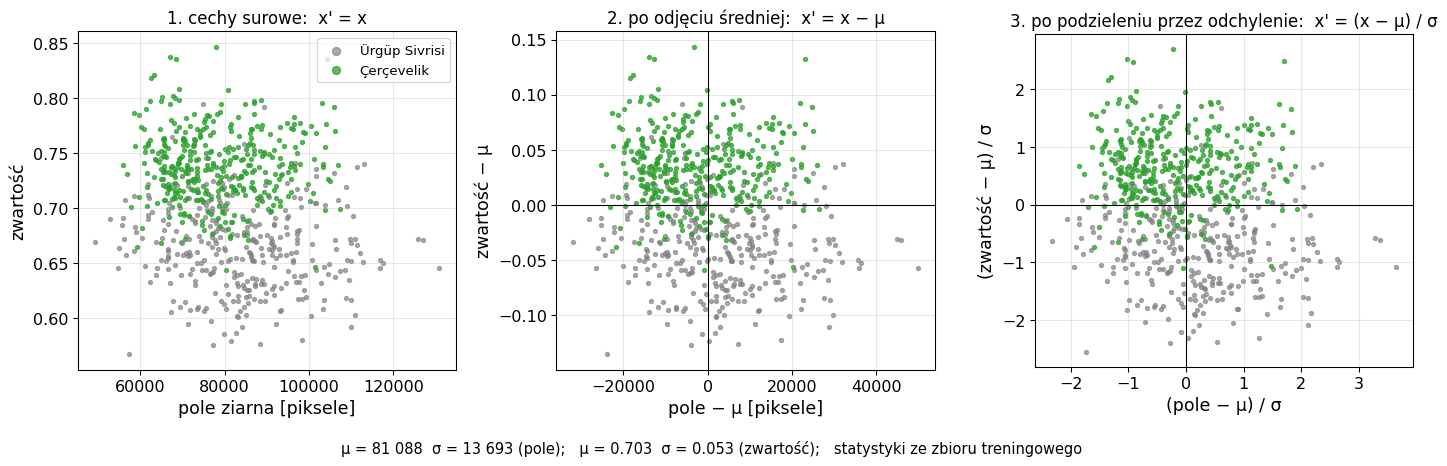

*Dwie cechy ze zbioru treningowego (pole ziarna i zwartość): surowe, po odjęciu średniej każdej cechy (środek chmury w zerze, skale osi bez zmian) i po podzieleniu przez odchylenie standardowe (obie osie w tych samych jednostkach: liczba odchyleń od średniej). Kolory to odmiany; po standaryzacji widać, że odmiany różnią się zwartością bardziej niż polem.*


In [ ]:
mean, std = X_train.mean(axis=0), X_train.std(axis=0) + 1e-8  # statystyki każdej cechy WYŁĄCZNIE ze zbioru treningowego
X_train, X_val, X_test = (X_train - mean) / std, (X_val - mean) / std, (X_test - mean) / std

print(f"po standaryzacji (zbiór treningowy):  średnia cech {X_train.mean():.3f}, odchylenie {X_train.std():.3f}")
print(f"zbiór walidacyjny tymi samymi statystykami: średnia {X_val.mean():.3f}, odchylenie {X_val.std():.3f}")
print(f"pole ziarna po standaryzacji: min {X_train[:, 0].min():.2f}, max {X_train[:, 0].max():.2f}")

po standaryzacji (zbiór treningowy):  średnia cech -0.000, odchylenie 1.000
zbiór walidacyjny tymi samymi statystykami: średnia -0.043, odchylenie 1.051
pole ziarna po standaryzacji: min -2.42, max 4.05


Średnią i odchylenie każdej cechy liczymy **raz, na zbiorze treningowym**, i tymi samymi liczbami przekształcamy walidację
i test. Etykiet `y` nie dotykamy: zostają 0/1, w kształcie `(N, 1)`, jakiego używały `sigmoid_bce_forward`
i `sigmoid_bce_backward` w Laboratorium 2.

> **Pułapka 1.** Statystyki policzone na całym zbiorze, razem z przykładami walidacyjnymi i testowymi, to **wyciek
> danych** (*data leakage*): informacja o danych, które mają udawać „nigdy nie widziane”, trafia do przetwarzania.
> Tu różnica byłaby znikoma (losowy podział, 2 500 przykładów), ale w praktyce dane testowe przychodzą później i mogą
> mieć inny rozkład, więc nawyk ma znaczenie. To samo dotyczy każdego innego przetwarzania wstępnego: wszystko, co ma
> parametry wyliczone z danych, liczymy na zbiorze treningowym.

### 1.3 Standaryzacja a normalizacja

Dwa przekształcenia sprowadzające cechy do wspólnej skali, oba liczone osobno dla każdej cechy $j$:

$$\text{standaryzacja:}\quad x'_j = \frac{x_j - \mu_j}{\sigma_j}
\qquad\qquad
\text{normalizacja min-max:}\quad x'_j = \frac{x_j - \min_j}{\max_j - \min_j}$$

Różnica jest w tym, **co** odejmujemy i **przez co** dzielimy: standaryzacja odejmuje średnią $\mu_j$ i dzieli przez
odchylenie standardowe $\sigma_j$, normalizacja odejmuje najmniejszą wartość $\min_j$ i dzieli przez rozstęp
$\max_j - \min_j$. Konsekwencje:

| | standaryzacja $(x - \mu) / \sigma$ | normalizacja min-max $(x - \min) / (\max - \min)$ |
|---|---|---|
| gdzie trafia typowa wartość | średnia w 0, odchylenie 1 | przedział $[0, 1]$: $\min \to 0$, $\max \to 1$ |
| zakres wyniku | nieograniczony (tu pole: od −2,42 do 4,05) | dokładnie $[0, 1]$ na zbiorze treningowym; nowe dane mogą wyjść poza przedział |
| wpływ jednej obserwacji odstającej | mały: nieznacznie zmienia $\mu$ i $\sigma$ | duży: ustala $\max$ (lub $\min$) i ściska pozostałe wartości w wąski podprzedział |
| dla pola ziarna 100 000 | $(100\,000 - 81\,088) / 13\,693 = 1{,}38$ | $(100\,000 - 47\,939) / (136\,574 - 47\,939) = 0{,}59$ |
| typowe zastosowanie | cechy tabelaryczne o różnych jednostkach (jak tu) | dane o naturalnym, znanym zakresie, np. piksele 0–255 → $[0, 1]$ (Lab 4) |

W obu przypadkach statystyki ($\mu$, $\sigma$ albo $\min$, $\max$) liczy się wyłącznie na zbiorze treningowym. Uwaga na
nazwy: w literaturze „normalizacja” bywa używana jako wspólna nazwa obu przekształceń, a w sieciach głębokich oznacza
też osobne warstwy (*batch normalization*, *layer normalization*), które normalizują pobudzenia **wewnątrz** sieci —
to temat Laboratorium 4.


## 2. Sieć i pętla uczenia

### 2.1 Klocki z Laboratorium 2

Wszystko, czego potrzebuje sieć, zbudowałeś(aś) w Laboratorium 2. Poniżej rozwiązania — te same sygnatury, ten sam kod;
jeśli chcesz, podmień je na własne. Do tego trzy narzędzia kontrolne z Lab 2: stabilny `sigmoid`, gradient numeryczny
i błąd względny.

| funkcja | rola w sieci |
|---|---|
| `linear_forward(X, W, b)`, `linear_backward(dout, X, W)` | warstwa liniowa: `X @ W + b`; backward dostaje te same wejścia co forward |
| `relu_forward(X)`, `relu_backward(dout, X)` | aktywacja w warstwie ukrytej |
| `sigmoid_bce_forward(z, y)`, `sigmoid_bce_backward(z, y)` | warstwa straty: sigmoid z binarną entropią krzyżową, gradient `(sigmoid(z) - y) / N` |
| `numerical_gradient`, `rel_error` | test gradientów w komórkach sprawdzających |


In [ ]:
def sigmoid(z):
    """Stabilny numerycznie sigmoid, element po elemencie: wynik ma kształt z i leży między 0 a 1."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))


def numerical_gradient(f, x, h=1e-5):
    """Gradient funkcji skalarnej f w punkcie x, liczony różnicą centralną (element po elemencie)."""
    grad = np.zeros_like(x)
    for i in np.ndindex(x.shape):
        old = x[i]
        x[i] = old + h
        fp = f(x)
        x[i] = old - h
        fm = f(x)
        x[i] = old
        grad[i] = (fp - fm) / (2 * h)
    return grad


def rel_error(a, b):
    """Największy błąd względny między dwiema tablicami."""
    return np.max(np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b)))


def linear_forward(X, W, b):
    """X: (N, D), W: (D, H), b: (H,) -> out: (N, H)."""
    return X @ W + b


def linear_backward(dout, X, W):
    """dout: (N, H), X: (N, D), W: (D, H) -> dX: (N, D), dW: (D, H), db: (H,)."""
    return dout @ W.T, X.T @ dout, dout.sum(axis=0)


def relu_forward(X):
    """X: dowolny kształt -> tablica o kształcie X."""
    return np.maximum(0, X)


def relu_backward(dout, X):
    """dout: kształt jak X, X: wejście ReLU -> dX (kształt jak dout)."""
    return dout * (X > 0)


def sigmoid_bce_forward(z, y):
    """z: (N, 1) logity, y: (N, 1) etykiety 0/1 -> wartość funkcji straty dla paczki: średnia ze strat przykładów (skalar)."""
    return np.mean(np.logaddexp(0, z) - y * z)


def sigmoid_bce_backward(z, y):
    """z: (N, 1), y: (N, 1) -> dz (N, 1) = (sigmoid(z) - y) / N."""
    return (sigmoid(z) - y) / len(y)

### 2.2 Algorytm pętli uczenia

Sieć, którą uczymy, ma jedną warstwę ukrytą: warstwa liniowa → ReLU → warstwa liniowa, która zwraca jeden logit na przykład.
Sigmoid i strata są już za nią, w warstwie straty:

$$X \;\xrightarrow{\;\text{linear}_1\;}\; Z_1 \;\xrightarrow{\;\text{ReLU}\;}\; H_1 \;\xrightarrow{\;\text{linear}_2\;}\; z \;\xrightarrow{\;\sigma\;}\; p \;\xrightarrow{\;\text{BCE}\;}\; L .$$

Parametry sieci trzymamy w słowniku `params` z czterema tablicami: `W1`, `b1`, `W2`, `b2`. Wagi losujemy ze skalą
$1/\sqrt{\text{liczba wejść}}$, żeby pobudzenia były rzędu 1 (dlatego standaryzowaliśmy cechy), biasy zerujemy:


In [ ]:
def init_params(D, H, seed=0):
    """Parametry sieci [D, H, 1]: wagi ze skalą 1/sqrt(liczby wejść), biasy zerowe."""
    rng_w = np.random.default_rng(seed)
    return {
        "W1": rng_w.normal(0, 1 / np.sqrt(D), (D, H)),
        "b1": np.zeros(H),
        "W2": rng_w.normal(0, 1 / np.sqrt(H), (H, 1)),
        "b2": np.zeros(1),
    }


params = init_params(X_train.shape[1], 32)
print({key: value.shape for key, value in params.items()}, "| liczba parametrów:", sum(v.size for v in params.values()))

{'W1': (12, 32), 'b1': (32,), 'W2': (32, 1), 'b2': (1,)} | liczba parametrów: 449


Uczenie to schemat z Lab 2 (sekcja 1) powtarzany w pętli. Jedna iteracja — jeden **krok uczenia** — składa się
z trzech funkcji, między którymi stoi warstwa straty:

```
powtarzaj:
    z, inputs = forward(params, X)              # 1. propagacja w przód: od danych do logitów
    loss = sigmoid_bce_forward(z, y)            #    wartość funkcji straty (do wydruku)
    dz = sigmoid_bce_backward(z, y)             #    gradient straty względem logitów: początek propagacji wstecznej
    grads = backward(params, inputs, dz)        # 2. propagacja wsteczna: gradient dla każdej tablicy parametrów
    optimizer_step(params, grads, lr)           # 3. krok optymalizacji: params[k] -= lr * grads[k]
```

| funkcja | co robi | co zwraca |
|---|---|---|
| `forward(params, X)` | wywołuje po kolei `linear_forward`, `relu_forward`, `linear_forward` | logity `z` o kształcie `(N, 1)` oraz `inputs` — wejścia warstw `(X, Z1, H1)`, bo każda funkcja backward potrzebuje **tych samych wejść, które dostał forward** |
| `backward(params, inputs, dz)` | te same warstwy w odwrotnej kolejności: `linear_backward`, `relu_backward`, `linear_backward`; `dX` jednej warstwy jest gradientem przychodzącym `dout` warstwy przed nią | słownik `grads` o tych samych kluczach co `params` |
| `optimizer_step(params, grads, lr)` | krok metody gradientu prostego z Lab 2, `w = w - lr * g`, dla każdej tablicy | nic — zmienia `params` w miejscu |

### Zadanie 1 (1 pkt) — `forward`, `backward`, `optimizer_step`

Napisz te trzy funkcje. Komórka sprawdzająca porównuje `forward` z ręcznym złożeniem warstw, gradienty z `backward`
z gradientem numerycznym straty względem każdej tablicy w `params` (jak w Lab 2, tylko dla całej sieci) i sprawdza,
że `optimizer_step` wykonuje dokładnie `params[k] -= lr * grads[k]`.


In [ ]:
def forward(params, X):
    """Propagacja w przód: liniowa -> ReLU -> liniowa. Zwraca logity (N, 1) oraz inputs = (X, Z1, H1) — wejścia warstw dla backward."""
    # --- TODO: tutaj wpisz swój kod ---
    Z1 = linear_forward(X, params['W1'], params['b1'])
    H1 = relu_forward(Z1)
    logits = linear_forward(H1, params['W2'], params['b2'])
    return logits, (X, Z1, H1)

def backward(params, inputs, dz):
    """Propagacja wsteczna: te same warstwy w odwrotnej kolejności. dz: gradient straty względem logitów (N, 1).

    Zwraca słownik gradientów o kluczach jak params: W1, b1, W2, b2.
    """
    # --- TODO: tutaj wpisz swój kod ---
    X, Z1, H1 = inputs
    dH1, dW2, db2 = linear_backward(dz, H1, params['W2'])
    dZ1 = relu_backward(dH1, Z1)
    dX, dW1, db1 = linear_backward(dZ1, X, params['W1'])
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}


def optimizer_step(params, grads, lr):
    """Krok metody gradientu prostego (w = w - lr * g) dla każdej tablicy parametrów, w miejscu."""
    # --- TODO: tutaj wpisz swój kod ---
    for key in params.keys():
        params[key] -= lr * grads[key]

In [ ]:
p_ = init_params(6, 5, seed=1)
X_, y_ = np.random.default_rng(22).normal(size=(4, 6)), np.array([[1.0], [0.0], [1.0], [0.0]])

# forward: logity i wejścia warstw
z_, inputs_ = forward(p_, X_)
assert z_.shape == (4, 1), "forward zwraca logity o kształcie (N, 1)"
Z1_ref = linear_forward(X_, p_["W1"], p_["b1"])
H1_ref = relu_forward(Z1_ref)
np.testing.assert_allclose(z_, linear_forward(H1_ref, p_["W2"], p_["b2"]), err_msg="logity: linear -> ReLU -> linear")
assert len(inputs_) == 3, "inputs to trzy tablice: X, Z1 (wejście ReLU), H1 (wejście drugiej warstwy liniowej)"
np.testing.assert_allclose(inputs_[1], Z1_ref, err_msg="inputs[1] to wejście ReLU (pobudzenia Z1, przed aktywacją)")
np.testing.assert_allclose(inputs_[2], H1_ref, err_msg="inputs[2] to wejście drugiej warstwy liniowej (H1, po aktywacji)")
print("forward: OK")

# backward: gradient każdej tablicy parametrów zgodny z gradientem numerycznym straty
grads_ = backward(p_, inputs_, sigmoid_bce_backward(z_, y_))
assert set(grads_) == set(p_), "grads ma te same klucze co params"
for key in p_:
    assert grads_[key].shape == p_[key].shape, f"{key}: gradient ma kształt swojego parametru"
    # numerical_gradient zmienia tablicę p_[key] w miejscu, więc stratę liczymy od nowa całym forward
    err = rel_error(grads_[key], numerical_gradient(lambda _: sigmoid_bce_forward(forward(p_, X_)[0], y_), p_[key]))
    assert err < 1e-6, f"{key}: błąd względny {err:.1e} — sprawdź kolejność warstw i wejścia przekazywane do backward"
    print(f"{key}: kształt {str(grads_[key].shape):8s} błąd względny {err:.1e}")
print("backward: OK")

# optimizer_step: params <- params - lr * grads, w miejscu
before = {key: value.copy() for key, value in p_.items()}
assert optimizer_step(p_, grads_, 0.1) is None, "optimizer_step zmienia params w miejscu i nic nie zwraca"
for key in p_:
    np.testing.assert_allclose(p_[key], before[key] - 0.1 * grads_[key], err_msg=f"{key}: krok to params - lr * grads")
print("optimizer_step: OK")
print("OK: Zadanie 1")

forward: OK
W1: kształt (6, 5)   błąd względny 3.0e-10
b1: kształt (5,)     błąd względny 4.7e-11
W2: kształt (5, 1)   błąd względny 3.1e-11
b2: kształt (1,)     błąd względny 1.5e-11
backward: OK
optimizer_step: OK
OK: Zadanie 1


### 2.3 Złożenie pętli uczenia

Pętla uczenia to powtarzanie trzech funkcji z Zadania 1 w kolejności z pseudokodu z punktu 2.2.

### Zadanie 2 (1 pkt) — `train_simple`

Złóż pętlę w najprostszej postaci: `steps` kroków, każdy na **całym** zbiorze `X, y` (tak jak w Lab 2 metoda gradientu
prostego robiła kroki na funkcji dwóch zmiennych). Funkcja zmienia `params` w miejscu i zwraca listę wartości straty —
po jednej na krok, liczonej **przed** krokiem (bo wtedy już ją mamy z propagacji w przód).

Komórka sprawdzająca porównuje jeden krok z ręcznym `params - lr * grads`, długość listy strat i to, że na naszych
danych strata maleje, a dokładność rośnie.


In [ ]:
def train_simple(params, X, y, lr, steps):
    """Metoda gradientu prostego na całym zbiorze: steps kroków forward -> strata -> backward -> optimizer_step.

    Zmienia params w miejscu; zwraca listę strat (po jednej na krok, liczonej przed krokiem).
    """
    losses = []
    # --- TODO: tutaj wpisz swój kod ---
    for _ in range(steps):
        logits, inputs = forward(params, X)
        loss = sigmoid_bce_forward(logits, y)
        losses.append(loss)
        dz = sigmoid_bce_backward(logits, y)
        grads = backward(params, inputs, dz)
        optimizer_step(params, grads, lr)
    return losses

In [ ]:
# (a) jeden krok: parametry po kroku = parametry przed - lr * gradient, strata liczona przed krokiem
p_a = init_params(6, 5, seed=3)
X_a, y_a = np.random.default_rng(3).normal(size=(8, 6)), np.array([[0.0], [1.0], [1.0], [0.0], [1.0], [0.0], [0.0], [1.0]])
before = {key: value.copy() for key, value in p_a.items()}
z_a, inputs_a = forward(p_a, X_a)
grads_a = backward(p_a, inputs_a, sigmoid_bce_backward(z_a, y_a))
losses_a = train_simple(p_a, X_a, y_a, lr=0.1, steps=1)
for key in before:
    np.testing.assert_allclose(p_a[key], before[key] - 0.1 * grads_a[key], atol=1e-12, err_msg=f"{key}: krok to params - lr * grads")
assert len(losses_a) == 1 and np.isclose(losses_a[0], sigmoid_bce_forward(z_a, y_a)), (
    "po jednym kroku: jedna strata, liczona przed krokiem"
)

# (b) kilka kroków: lista strat ma długość steps i przy małym lr maleje w każdym kroku
losses_b = train_simple(init_params(6, 5, seed=3), X_a, y_a, lr=0.05, steps=20)
assert len(losses_b) == 20, "po jednej stracie na krok"
assert all(b < a for a, b in zip(losses_b, losses_b[1:])), "przy małym lr strata powinna maleć z każdym krokiem"

# (c) na danych: strata spada, dokładność rośnie
p_c = init_params(X_train.shape[1], 32, seed=0)
losses_c = train_simple(p_c, X_train, y_train, lr=0.5, steps=300)
z_c, _ = forward(p_c, X_train)
acc_c = ((z_c > 0) == (y_train == 1)).mean()
assert losses_c[-1] < 0.5 * losses_c[0], "po 300 krokach strata powinna spaść co najmniej o połowę"
assert acc_c > 0.8, f"dokładność treningowa po 300 krokach to {acc_c:.3f}, oczekiwano > 0.8"
print(f"OK: Zadanie 2 | strata {losses_c[0]:.3f} -> {losses_c[-1]:.3f}, dokładność treningowa {acc_c:.3f}")

OK: Zadanie 2 | strata 0.821 -> 0.280, dokładność treningowa 0.885


In [ ]:
params = init_params(X_train.shape[1], 32, seed=0)
t0 = time.perf_counter()
losses = train_simple(params, X_train, y_train, lr=0.5, steps=300)
elapsed = time.perf_counter() - t0
for step in [1, 50, 100, 150, 200, 250, 300]:
    print(f"krok {step:3d}: strata {losses[step - 1]:.4f}")
print(f"czas 300 kroków: {elapsed:.2f} s, czyli {1000 * elapsed / 300:.1f} ms na krok")

z_val, _ = forward(params, X_val)
print(f"dokładność walidacyjna po 300 krokach: {((z_val > 0) == (y_val == 1)).mean():.3f}")

krok   1: strata 0.8213
krok  50: strata 0.3027
krok 100: strata 0.2940
krok 150: strata 0.2890
krok 200: strata 0.2853
krok 250: strata 0.2826
krok 300: strata 0.2805
czas 300 kroków: 0.32 s, czyli 1.1 ms na krok
dokładność walidacyjna po 300 krokach: 0.904


Strata startowa wynosi 0,82, nieco powyżej log 2 ≈ 0,69, bo losowe wagi dają niezerowe logity. Po 50 krokach strata spada do 0,30, po 300 — do 0,28; dokładność treningowa to 0,885, walidacyjna 0,904. Do tego wyniku wystarczyły funkcje z Lab 2 i trzy funkcje z Zadania 1.

Pętla używana w praktyce różni się od tej dwoma elementami, opisanymi w punkcie 2.4.


### 2.4 Mini-paczki, epoki i walidacja

**Mini-paczki.** Każdy z 300 kroków powyżej przeliczył wszystkie 1 500 przykładów, a dał tylko jedną aktualizację
parametrów. Zamiast tego gradient liczymy na kolejnych **mini-paczkach** (*mini-batch*) po `batch_size` przykładów
(Lab 2, sekcja 1): jedna mini-paczka to jeden krok, więc jedno przejście przez zbiór daje `N / batch_size` kroków
zamiast jednego. Takie przejście, mini-paczka po mini-paczce, to **epoka** (*epoch*). Na początku każdej epoki
przykłady tasujemy, żeby mini-paczki były za każdym razem inne. Gradient z mini-paczki jest losowym przybliżeniem
gradientu z całego zbioru, stąd nazwa tej wersji: **stochastyczny spadek gradientu** (*stochastic gradient descent*, SGD).

**Walidacja.** Dokładność treningową liczyliśmy przy okazji, na tych samych przykładach, na których robiliśmy krok —
a ta potrafi kłamać (sekcja 3). Po każdej epoce liczymy więc dokładność na całym zbiorze treningowym **i** na zbiorze
walidacyjnym i zapisujemy obie razem ze średnią stratą mini-paczek w słowniku `history`. Dokładność liczy gotowa funkcja:


In [ ]:
def accuracy(params, X, y):
    """Odsetek poprawnych predykcji; klasa 1, gdy logit > 0 (próg 0,5 na sigmoidzie)."""
    z, _ = forward(params, X)
    return ((z > 0) == (y == 1)).mean()


print(f"dokładność sieci z punktu 2.3 na zbiorze walidacyjnym: {accuracy(params, X_val, y_val):.3f}")

dokładność sieci z punktu 2.3 na zbiorze walidacyjnym: 0.904


Funkcja `train` poniżej to `train_simple` z Zadania 2 z czterema dopiskami — każdy odpowiada jednej linii albo
jednemu blokowi w kodzie:

| co nowego | gdzie w kodzie |
|---|---|
| epoki i mini-paczki: tasowanie indeksów, pętla po kawałkach po `batch_size` (ostatni może być mniejszy) | `order = order_rng.permutation(...)`, `for start in range(0, N, batch_size)` |
| krok uczenia bez zmian, tylko na mini-paczce | `forward_fn` → `sigmoid_bce_forward` → `sigmoid_bce_backward` → `backward_fn` → `optimizer_step` |
| pomiar po epoce: średnia strata mini-paczek, dokładność treningowa i walidacyjna, czas epoki | `history[...].append(...)`, `time.perf_counter()` |
| hak na wczesne zatrzymanie: po epoce `early_stopping.step(val_acc)`; `True` przerywa uczenie | ostatni `if` (klasę `EarlyStopping` napiszesz w sekcji 4) |

Argumenty `forward_fn` i `backward_fn` to domyślnie Twoje `forward` i `backward` z Zadania 1; w sekcji 4 podmienimy je
na wersję z dropoutem. Dokładność zawsze liczy `accuracy`, czyli zwykły `forward`.

**Czas epoki.** `history["epoch_time"]` to czas samych kroków uczenia w epoce (bez pomiaru dokładności). Mierzy się go
z trzech powodów: żeby oszacować całkowity czas uczenia przed jego końcem (czas epoki × liczba epok), żeby porównywać
koszt konfiguracji — większy `batch_size` to mniej kroków na epokę, ale droższy krok; większa sieć to droższy krok —
i żeby wykryć, kiedy czas idzie nie na obliczenia, lecz na przygotowanie danych. W Laboratorium 4 ten sam pomiar
pokaże, ile daje GPU.


In [ ]:
def train(
    params,
    X_train,
    y_train,
    X_val,
    y_val,
    lr=0.05,
    epochs=10,
    batch_size=32,
    early_stopping=None,
    seed=0,
    verbose=False,
    forward_fn=forward,
    backward_fn=backward,
):
    """SGD na mini-paczkach. Zwraca history: słownik list train_loss, train_acc, val_acc, epoch_time (po jednym elemencie na epokę)."""
    order_rng = np.random.default_rng(seed)
    history = {"train_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    for epoch in range(epochs):
        t0 = time.perf_counter()
        order = order_rng.permutation(len(X_train))  # kolejność przykładów w tej epoce
        losses = []
        for start in range(0, len(X_train), batch_size):
            batch = order[start : start + batch_size]
            z, inputs = forward_fn(params, X_train[batch])  # 1. propagacja w przód
            losses.append(sigmoid_bce_forward(z, y_train[batch]))  # wartość funkcji straty
            dz = sigmoid_bce_backward(z, y_train[batch])
            grads = backward_fn(params, inputs, dz)  # 2. propagacja wsteczna
            optimizer_step(params, grads, lr)  # 3. krok optymalizacji
        history["epoch_time"].append(time.perf_counter() - t0)  # czas samych kroków uczenia, bez pomiaru dokładności
        history["train_loss"].append(np.mean(losses))
        history["train_acc"].append(accuracy(params, X_train, y_train))
        history["val_acc"].append(accuracy(params, X_val, y_val))
        if verbose:
            print(
                f"epoka {epoch + 1:2d}: strata {history['train_loss'][-1]:.4f}   "
                f"dokładność treningowa {history['train_acc'][-1]:.3f}   walidacyjna {history['val_acc'][-1]:.3f}   "
                f"czas {1000 * history['epoch_time'][-1]:.0f} ms"
            )
        if early_stopping is not None and early_stopping.step(history["val_acc"][-1]):
            if verbose:
                print(f"wczesne zatrzymanie po epoce {epoch + 1}")
            break
    return history

In [ ]:
params = init_params(X_train.shape[1], 64, seed=42)
history = train(params, X_train, y_train, X_val, y_val, lr=0.05, epochs=10, verbose=True)
n_batches = -(-len(X_train) // 32)  # liczba mini-paczek w epoce (zaokrąglenie w górę)
epoch_ms = 1000 * np.mean(history["epoch_time"])
print(f"najlepsza dokładność walidacyjna: {max(history['val_acc']):.3f} w epoce {int(np.argmax(history['val_acc'])) + 1}")
print(f"średni czas epoki: {epoch_ms:.0f} ms = {n_batches} kroków po {epoch_ms / n_batches:.2f} ms")

epoka  1: strata 0.4303   dokładność treningowa 0.863   walidacyjna 0.886   czas 9 ms
epoka  2: strata 0.3298   dokładność treningowa 0.870   walidacyjna 0.896   czas 8 ms
epoka  3: strata 0.3209   dokładność treningowa 0.875   walidacyjna 0.898   czas 8 ms
epoka  4: strata 0.3174   dokładność treningowa 0.877   walidacyjna 0.890   czas 8 ms
epoka  5: strata 0.3148   dokładność treningowa 0.877   walidacyjna 0.898   czas 8 ms
epoka  6: strata 0.3126   dokładność treningowa 0.877   walidacyjna 0.900   czas 8 ms
epoka  7: strata 0.3121   dokładność treningowa 0.876   walidacyjna 0.902   czas 8 ms
epoka  8: strata 0.3095   dokładność treningowa 0.876   walidacyjna 0.898   czas 8 ms
epoka  9: strata 0.3083   dokładność treningowa 0.877   walidacyjna 0.898   czas 7 ms
epoka 10: strata 0.3075   dokładność treningowa 0.876   walidacyjna 0.900   czas 7 ms
najlepsza dokładność walidacyjna: 0.902 w epoce 7
średni czas epoki: 8 ms = 47 kroków po 0.17 ms


Dziesięć epok (po 47 mini-paczek, ok. 470 kroków) daje ok. 0,90 dokładności walidacyjnej (najwyżej 0,902 w epoce 7) — tyle samo, co 300 kroków pełną paczką, przy czym każdy krok przetwarza 32 przykłady zamiast 1 500. Dokładność walidacyjna jest tu nieco wyższa od treningowej; przy 500 przykładach walidacyjnych błąd standardowy pomiaru wynosi ok. 0,013, więc różnica mieści się w szumie. Krzywe nie są monotoniczne: gradient z mini-paczki jest losowym przybliżeniem gradientu z całego zbioru, więc stan sieci po ostatniej mini-paczce epoki bywa gorszy niż kilka kroków wcześniej.

| element | działanie |
|---|---|
| epoka | jedno przejście przez cały zbiór treningowy, mini-paczka po mini-paczce |
| `order_rng.permutation(N)` | nowa kolejność przykładów w każdej epoce |
| `order[start : start + batch_size]` | indeksy jednej mini-paczki |
| `forward_fn` → strata → `backward_fn` → `optimizer_step` | krok uczenia z Zadania 2, tylko na mini-paczce |
| `history` | po jednej liczbie na epokę: strata, dokładność treningowa, dokładność walidacyjna, czas epoki |

Hiperparametry pętli to `lr`, `epochs` i `batch_size`; parametry to zawartość `params`. Zbiór walidacyjny nie
bierze udziału w żadnym kroku gradientowym — służy do pomiaru i do wczesnego zatrzymania (sekcja 4).

**Pytanie kontrolne.** 300 kroków pełną paczką i 10 epok po 47 mini-paczek dają tu podobną dokładność. Porównaj czas
kroku w obu wariantach (wydruki wyżej) i liczbę przetworzonych przykładów. Który z nich zadziała, gdy zbiór treningowy
nie mieści się w pamięci?


### 2.5 Logowanie metryk

Słownik `history` to **dziennik uczenia** (*training log*): po każdej epoce zapisana strata treningowa (średnia z mini-paczek),
dokładność treningowa i walidacyjna oraz czas epoki. Logowanie metryk nie wpływa na uczenie, ale bez niego uczenie jest
czarną skrzynką. Logi służą do:

- **diagnozy** — krzywe uczenia pokazują przeuczenie i niedouczenie (sekcja 3), za duży `lr` (strata skacze lub rośnie)
  i za mały (strata ledwo maleje) szybciej niż końcowy wynik,
- **decyzji w trakcie** — wczesne zatrzymanie (sekcja 4) i wybór najlepszej epoki działają na zalogowanej dokładności walidacyjnej,
- **porównywania przebiegów** — różne hiperparametry zestawia się na jednym wykresie, z tych samych metryk,
- **odtwarzalności** — zapisany log pozwala wrócić do przebiegu bez ponownego uczenia.

Dwie zasady praktyczne: stratę treningową logujemy tanio, jako średnią strat mini-paczek liczonych i tak w każdym kroku;
dokładność walidacyjną liczymy raz na epokę (a przy bardzo dużych zbiorach co ustaloną liczbę kroków), bo każdy pomiar
to dodatkowa propagacja w przód przez cały zbiór. W praktyce logi trafiają do narzędzi takich jak TensorBoard czy
Weights & Biases, które rysują te same krzywe na żywo — wrócimy do tego w Laboratorium 4. W sekcjach 3 i 4 z dziennika
korzystają dwie funkcje pomocnicze: wykres krzywych uczenia i tabela wyników.


## 3. Przeuczenie i niedouczenie

Sieć uczy się minimalizować stratę **na zbiorze treningowym** — tylko to widzi gradient. Nam chodzi o coś innego:
o trafne odpowiedzi na nowych przykładach. Te dwa cele pokrywają się dopóty, dopóki sieć uczy się tego, co odróżnia
klasy. Ale sieć z tysiącami parametrów potrafi też nauczyć się czegoś innego: **zapamiętać** przykłady treningowe wraz
z ich przypadkowymi cechami. Wtedy strata treningowa dalej maleje, a dokładność na nowych danych przestaje rosnąć
albo spada. To **przeuczenie** (*overfitting*). Sprzyjają mu: dużo parametrów, mało danych, długie uczenie.

Demonstracja: sieć `[D, 256, 1]` (prawie cztery tysiące parametrów) uczona na **100** przykładach treningowych,
z większym krokiem (`lr = 0.2`) przez 300 epok; po każdej epoce mierzymy dokładność treningową i walidacyjną.
Wykres krzywych uczenia i tabelę wyników rysują dwie funkcje pomocnicze (z dziennika `history`, punkt 2.5), używane też w sekcji 4:


In [ ]:
def plot_history(histories, title):
    """Krzywe uczenia z dziennika: strata treningowa (lewy panel) oraz dokładność walidacyjna (ciągła) i treningowa (przerywana)."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.3))
    for name, hist in histories.items():
        epochs = range(1, len(hist["val_acc"]) + 1)
        (line,) = ax_loss.plot(epochs, hist["train_loss"], label=name, linewidth=2)
        ax_acc.plot(epochs, hist["val_acc"], label=f"{name}: walidacja", linewidth=2, color=line.get_color())
        ax_acc.plot(epochs, hist["train_acc"], label=f"{name}: trening", linewidth=1.2, linestyle="--", color=line.get_color())
    ax_loss.set_xlabel("epoka")
    ax_loss.set_ylabel("strata treningowa")
    ax_loss.set_title("strata")
    ax_acc.set_xlabel("epoka")
    ax_acc.set_ylabel("dokładność")
    ax_acc.set_title("dokładność")
    for ax in (ax_loss, ax_acc):
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def print_summary(histories):
    """Tabela: liczba epok, końcowa dokładność treningowa i walidacyjna, luka i łączny czas uczenia dla każdej historii."""
    print(f"{'':34s} {'epok':>5s} {'dokł. tren.':>12s} {'dokł. walid.':>13s} {'luka':>7s} {'czas [s]':>9s}")
    for name, hist in histories.items():
        train_acc, val_acc = hist["train_acc"][-1], hist["val_acc"][-1]
        total_time = sum(hist["epoch_time"])
        print(f"{name:34s} {len(hist['val_acc']):5d} {train_acc:12.3f} {val_acc:13.3f} {train_acc - val_acc:7.3f} {total_time:9.2f}")

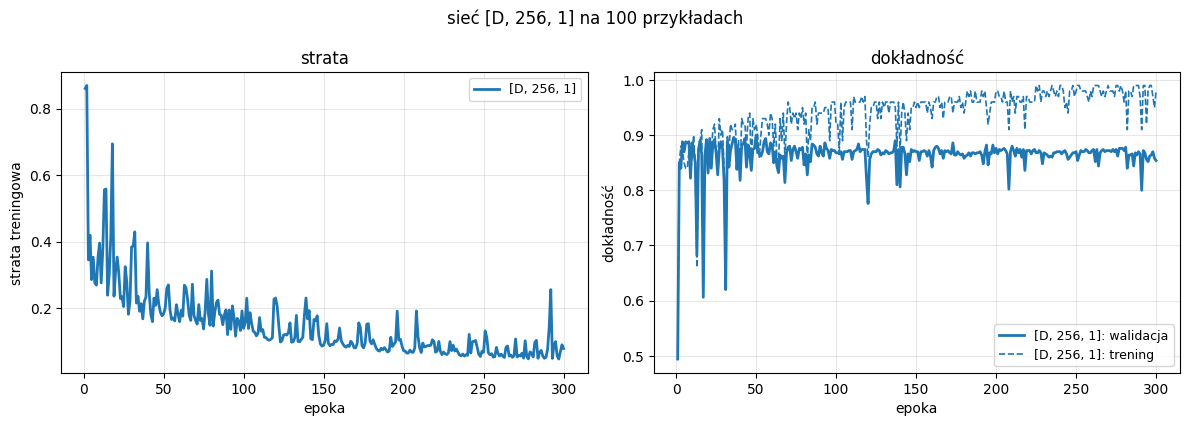

                                    epok  dokł. tren.  dokł. walid.    luka  czas [s]
[D, 256, 1]                          300        0.980         0.854   0.126      0.29
najlepsza dokładność walidacyjna: 0.900 w epoce 50


In [ ]:
X_subset, y_subset = (
    X_train[:100],
    y_train[:100],
)  # podzbiór zbioru treningowego: pierwsze 100 przykładów (X_train jest już przetasowany)
EPOCHS_SUBSET, LR_SUBSET = 300, 0.2  # liczba epok i współczynnik uczenia dla demonstracji na tym podzbiorze

params_overfit = init_params(X_train.shape[1], 256, seed=42)
history_overfit = train(params_overfit, X_subset, y_subset, X_val, y_val, lr=LR_SUBSET, epochs=EPOCHS_SUBSET)

plot_history({"[D, 256, 1]": history_overfit}, f"sieć [D, 256, 1] na {len(X_subset)} przykładach")
print_summary({"[D, 256, 1]": history_overfit})
best = int(np.argmax(history_overfit["val_acc"]))
print(f"najlepsza dokładność walidacyjna: {history_overfit['val_acc'][best]:.3f} w epoce {best + 1}")

Dokładność treningowa rośnie do 0,98 (sieć zapamiętała prawie wszystkie 100 przykładów), a walidacyjna osiąga 0,90 około epoki 50 i potem **spada** do 0,85; po 300 epokach luka wynosi 0,13. Odstęp między obiema krzywymi to **luka uogólnienia** (*generalization gap*): miara tego,
ile z dokładności treningowej jest zapamiętywaniem, a nie uczeniem. Przeuczoną sieć rozpoznasz po krzywych: treningowa
rośnie, walidacyjna staje lub spada, luka się rozszerza.


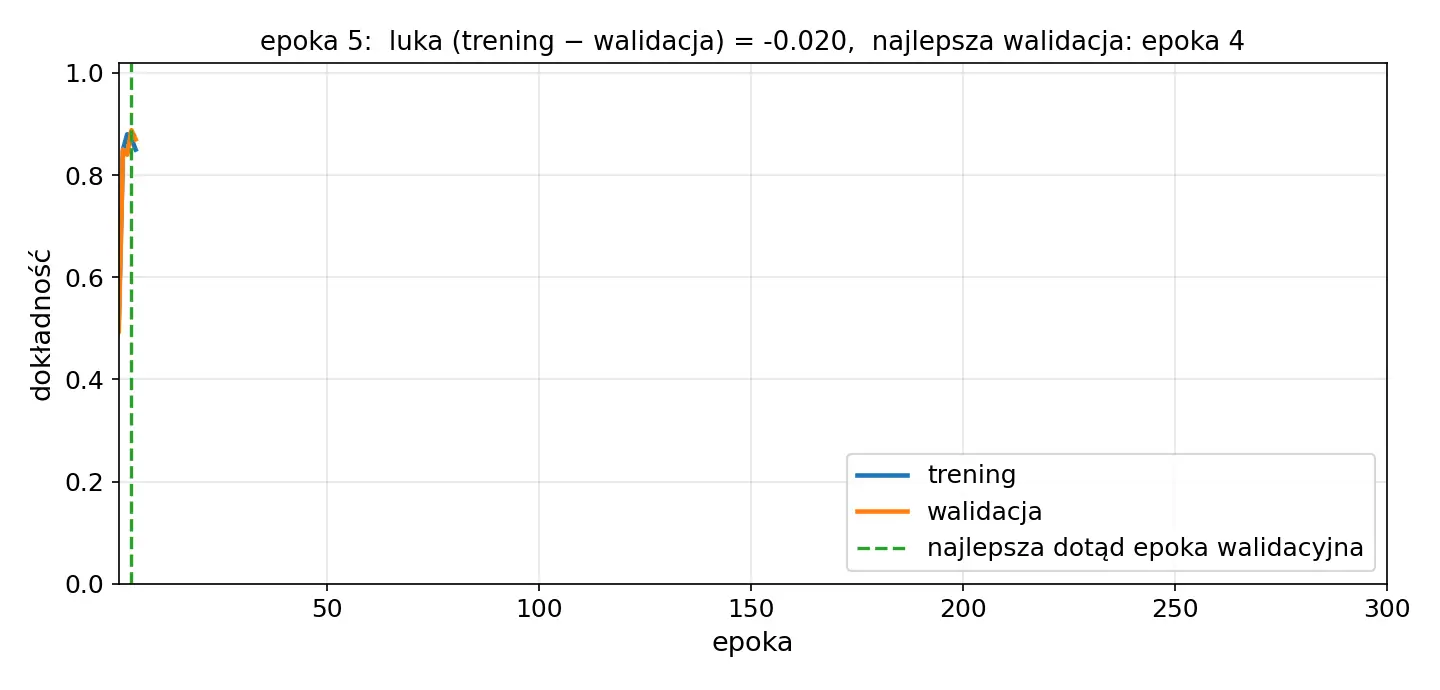

*Te same krzywe epoka po epoce. Czerwone pole to luka między dokładnością treningową a walidacyjną, zielona linia wskazuje najlepszą dotąd epokę walidacyjną — tę informację wykorzysta wczesne zatrzymanie.*


### Niedouczenie

Sytuacja odwrotna: sieć, która **nie zdążyła** albo **nie jest w stanie** uchwycić zależności między cechami a klasą —
za krótko uczona, ze zbyt małym `lr`, albo zbyt prosta. Wtedy obie dokładności są niskie i blisko siebie: luki nie ma,
bo nie ma czego zapamiętywać. To **niedouczenie** (*underfitting*). Te same 100 przykładów i ta sama liczba
epok, sieć o **jednym** neuronie ukrytym, uczona z krokiem dwieście razy mniejszym (`lr = 0.001`) oraz — dla
rozdzielenia przyczyn — ta sama sieć z krokiem `lr = 0.2`:


In [ ]:
params_underfit = init_params(X_train.shape[1], 1, seed=42)
history_underfit = train(params_underfit, X_subset, y_subset, X_val, y_val, lr=0.001, epochs=EPOCHS_SUBSET)
params_one = init_params(X_train.shape[1], 1, seed=42)
history_one = train(params_one, X_subset, y_subset, X_val, y_val, lr=LR_SUBSET, epochs=EPOCHS_SUBSET)

print_summary(
    {
        "[D, 1, 1], lr = 0.001": history_underfit,
        "[D, 1, 1], lr = 0.2": history_one,
        "[D, 256, 1], lr = 0.2": history_overfit,
    }
)

                                    epok  dokł. tren.  dokł. walid.    luka  czas [s]
[D, 1, 1], lr = 0.001                300        0.500         0.482   0.018      0.11
[D, 1, 1], lr = 0.2                  300        0.910         0.858   0.052      0.10
[D, 256, 1], lr = 0.2                300        0.980         0.854   0.126      0.29


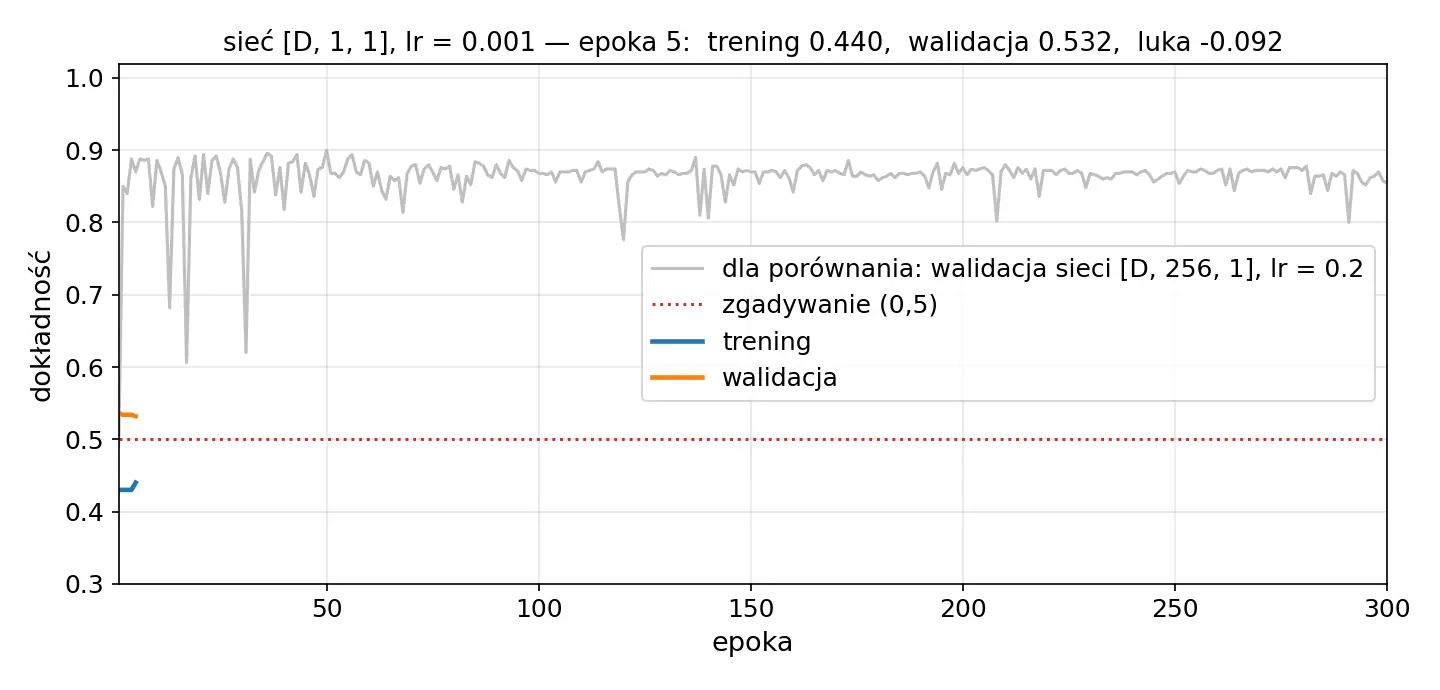

*Sieć [D, 1, 1] z lr = 0.001 epoka po epoce: obie dokładności zostają blisko 0,5 i blisko siebie — nie ma luki, bo nie ma czego zapamiętywać. Szara linia to walidacja sieci [D, 256, 1] z wykresu wyżej.*


Z krokiem 0,001 sieć o jednym neuronie ma po 300 epokach 0,50 na treningu i 0,48 na walidacji — dokładność losowa, bez luki: wagi zmieniły się o ok. 2 % i sieć niczego się nie nauczyła. Ta sama sieć z krokiem 0,2 osiąga 0,91 / 0,86, czyli tyle, ile sieć 256-neuronowa. Wniosek: na tym zbiorze granica między odmianami jest niemal liniowa i jeden neuron wystarcza; niedouczenie wywołał zbyt mały krok, nie rozmiar sieci. Zbyt mała sieć daje ten sam obraz (obie dokładności niskie, bez luki) na danych o bardziej złożonej zależności.

| objaw | diagnoza | co pomaga |
|---|---|---|
| dokładność treningowa wysoka, walidacyjna dużo niższa, luka rośnie z epokami | przeuczenie | więcej danych, krótsze uczenie (wczesne zatrzymanie), dropout, mniejsza sieć |
| obie dokładności niskie i blisko siebie | niedouczenie | większa sieć, dłuższe uczenie, większy `lr` |
| obie wysokie i blisko siebie | sieć dobrana do danych | — |

Więcej danych to najlepsze lekarstwo na przeuczenie, ale rzadko mamy je pod ręką. Sekcja 4 pokazuje dwa sposoby,
które działają przy tych samych danych.

**Pytanie kontrolne.** Patrząc tylko na krzywą walidacyjną z wykresu wyżej, w której epoce przerwał(a)byś uczenie?


## 4. Wczesne zatrzymanie i dropout

### 4.1 Wczesne zatrzymanie

Na krzywych z sekcji 3 dokładność walidacyjna przestaje rosnąć w okolicach epoki wskazanej zieloną linią, a treningowa
rośnie dalej: od tej epoki sieć już tylko zapamiętuje. **Wczesne zatrzymanie** (*early stopping*) wykorzystuje tę
obserwację: po każdej epoce sprawdza dokładność walidacyjną i przerywa uczenie, gdy przez `patience` kolejnych epok nie
poprawiła się o więcej niż `min_delta`. Nie zmienia straty ani gradientów — decyduje wyłącznie o momencie zakończenia.
Liczbę epok, którą trzeba było zgadywać, zastępuje hiperparametr `patience`.

W pętli `train` hak już jest: `early_stopping.step(val_acc)` po każdej epoce. Po zatrzymaniu wagi pochodzą z **ostatniej**
epoki, czyli o `patience` epok późniejszej niż najlepsza; w praktyce zapisuje się kopię wag z najlepszej epoki i po
zatrzymaniu do niej wraca (w Keras: `restore_best_weights`).

### 4.2 Dropout

**Dropout** (Srivastava i in., 2014) ogranicza przeuczenie inaczej. Zapamiętywanie przykładu można rozumieć tak:
konkretny układ neuronów aktywuje się razem tylko dla niego. Dropout rozbija takie układy: podczas uczenia w każdym kroku
**losowo wyłącza** część neuronów ukrytych — każdy z prawdopodobieństwem $p$, w każdym kroku inne. Sieć nie może polegać
na pojedynczym neuronie ani na stałym układzie neuronów, bo w następnej mini-paczce może ich zabraknąć; reprezentacja
musi być rozłożona na wiele neuronów. Żeby oczekiwana wartość aktywacji nie zmalała, neurony, które zostały,
**dzielimy przez $1 - p$** (*inverted dropout*). W trybie testowym — przy liczeniu dokładności — dropout nie działa: liczy
cała sieć, bez maski i bez skalowania; dzięki skalowaniu w czasie uczenia niczego nie trzeba wtedy przeliczać.

Dropout to warstwa jak każda inna, z parą `forward`/`backward` — z jedną nowością. Dotąd każdy backward dostawał to, co
forward otrzymał w argumentach; backward dropoutu potrzebuje czegoś, co forward **wylosował**: maski. Dlatego
`dropout_forward` zwraca ją obok wyniku, a `forward` sieci przekazuje dalej w `inputs`, jak wejścia pozostałych warstw.

> **Pułapka 2.** W pracy Srivastavy i w części materiałów (np. CS231n) $p$ oznacza prawdopodobieństwo **zachowania**
> neuronu, a w PyTorch (`nn.Dropout(p)`) i w tym notatniku — prawdopodobieństwo **wyłączenia**. Ta sama liczba 0,3
> znaczy w jednej konwencji 30 %, a w drugiej 70 % wyłączonych neuronów.

### Zadanie 3 (1 pkt) — `EarlyStopping`, `dropout_forward`, `dropout_backward`

- `EarlyStopping(patience, min_delta=0.0)` z metodą `step(val_metric) -> bool`: poprawa to wynik większy od najlepszego
  dotąd o więcej niż `min_delta` i zeruje licznik epok bez poprawy; `step` zwraca `True`, gdy licznik osiągnie `patience`.
- `dropout_forward(X, p, rng)` → `(out, mask)`: losuje z `rng` maskę (`True` = neuron zostaje, z prawdopodobieństwem
  `1 - p`), zeruje wyłączone elementy i dzieli resztę przez `1 - p`.
- `dropout_backward(dout, mask, p)` → gradient przez te same neurony z tym samym skalowaniem.


In [ ]:
class EarlyStopping:
    """Sygnał końca uczenia po `patience` kolejnych epokach bez poprawy o więcej niż `min_delta`."""

    def __init__(self, patience, min_delta=0.0):
        # --- TODO: tutaj wpisz swój kod ---
        self.patience = patience
        self.min_delta = min_delta
        self.best_metric = -float('inf')
        self.counter = 0

    def step(self, val_metric):
        """Zwraca True, gdy trzeba przerwać uczenie (większa metryka = lepiej)."""
        # --- TODO: tutaj wpisz swój kod ---
        if val_metric > self.best_metric + self.min_delta:
            self.best_metric = val_metric
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

def dropout_forward(X, p, rng):
    """X: (N, H), p: prawdopodobieństwo wyłączenia, rng: np.random.Generator -> (out, mask).

    Zeruje każdy element z prawdopodobieństwem p i dzieli resztę przez 1 - p; mask: True tam, gdzie element został.
    """
    # --- TODO: tutaj wpisz swój kod ---
    mask = rng.random(X.shape) > p
    out = (X * mask) / (1.0 - p)
    return out, mask


def dropout_backward(dout, mask, p):
    """Gradient tylko przez neurony, które zostały, z tym samym skalowaniem 1 / (1 - p)."""
    # --- TODO: tutaj wpisz swój kod ---
    return (dout * mask) / (1.0 - p)

In [ ]:
# wczesne zatrzymanie
def first_stop(es, values):
    # indeks epoki, po której EarlyStopping każe przerwać, albo None
    for i, v in enumerate(values):
        if es.step(v):
            return i
    return None


# indeks 1 (epoka 2) jest najlepszy: 0.759 nie przebija 0.75 o więcej niż 0.01, potem trzy epoki bez poprawy (indeksy 2-4)
assert first_stop(EarlyStopping(patience=3, min_delta=0.01), [0.70, 0.75, 0.759, 0.755, 0.754, 0.753, 0.752]) == 4, (
    "min_delta: 0.759 nie jest poprawą o więcej niż 0.01"
)
# poprawa w indeksie 3 (epoka 4) zeruje licznik
assert first_stop(EarlyStopping(patience=2), [0.50, 0.60, 0.59, 0.65, 0.64, 0.63]) == 5, (
    "licznik epok bez poprawy zeruje się po poprawie"
)
assert first_stop(EarlyStopping(patience=2), [0.1, 0.2, 0.3, 0.4]) is None, (
    "przy stale rosnącej metryce uczenie nie powinno się zatrzymać"
)
assert first_stop(EarlyStopping(patience=2), [0.5, 0.6, 0.6, 0.6]) == 3, "wynik równy najlepszemu nie jest poprawą"
print("EarlyStopping: OK | zatrzymanie dokładnie po patience epokach bez poprawy")

# dropout
rng_ = np.random.default_rng(10)
X_ = np.ones((200, 200))
out1, mask1 = dropout_forward(X_, p=0.2, rng=rng_)
out2, _ = dropout_forward(X_, p=0.2, rng=rng_)
assert mask1.shape == X_.shape and mask1.dtype == bool, "maska to tablica bool o kształcie X"
assert abs((out1 == 0).mean() - 0.2) < 0.02, "p to prawdopodobieństwo WYŁĄCZENIA: przy p = 0.2 zeruje się ok. 20 % elementów"
np.testing.assert_array_equal(out1 == 0, ~mask1, err_msg="wyzerowane są dokładnie elementy z mask == False")
assert abs(out1.mean() - 1.0) < 0.03, "po podzieleniu przez 1 - p średnia aktywacji nie powinna się zmienić"
assert not np.array_equal(out1, out2), "kolejne wywołania z tym samym generatorem muszą losować nowe maski"
out_a, _ = dropout_forward(X_[:20, :20], p=0.5, rng=np.random.default_rng(7))
out_b, _ = dropout_forward(X_[:20, :20], p=0.5, rng=np.random.default_rng(7))
np.testing.assert_array_equal(out_a, out_b, err_msg="maskę losujemy z przekazanego rng: ten sam seed generatora, ta sama maska")
dX = dropout_backward(np.ones_like(X_), mask1, 0.2)
np.testing.assert_array_equal(dX == 0, out1 == 0, err_msg="gradient przechodzi tylko przez neurony, które zostały")
np.testing.assert_allclose(dX[dX != 0], 1 / 0.8, err_msg="gradient ma to samo skalowanie 1 / (1 - p)")
# gradient dropoutu zgodny z numerycznym przy ustalonej masce
X_s, dout_s = rng_.normal(size=(4, 6)), rng_.normal(size=(4, 6))
_, mask_s = dropout_forward(X_s, 0.5, rng_)
num = numerical_gradient(lambda x: (x * mask_s / 0.5 * dout_s).sum(), X_s.copy())
assert rel_error(dropout_backward(dout_s, mask_s, 0.5), num) < 1e-6
print(f"dropout: OK | wyzerowanych elementów {(out1 == 0).mean():.3f} przy p = 0.2, nowa maska w każdym wywołaniu")
print("OK: Zadanie 3")

EarlyStopping: OK | zatrzymanie dokładnie po patience epokach bez poprawy
dropout: OK | wyzerowanych elementów 0.202 przy p = 0.2, nowa maska w każdym wywołaniu
OK: Zadanie 3


Dropout w sieci: `forward_dropout` to `forward` z Zadania 1 z jedną dodatkową linią po ReLU (maska trafia do `inputs`),
`backward_dropout` to `backward` z jedną dodatkową linią w tym samym miejscu, w odwrotnej kolejności. Obie funkcje służą
wyłącznie do kroków uczenia (`forward_fn`, `backward_fn` w `train`); dokładność liczy nadal `accuracy` zwykłym `forward`,
co odpowiada trybowi testowemu: cała sieć, bez maski.


In [ ]:
DROPOUT_P = 0.5  # prawdopodobieństwo wyłączenia neuronu ukrytego
dropout_rng = np.random.default_rng(0)  # generator masek — osobny od generatora wag i od tasowania


def forward_dropout(params, X):
    """forward z Zadania 1 plus dropout po ReLU. inputs = (X, Z1, H1, mask); H1 to już wyjście dropoutu."""
    Z1 = linear_forward(X, params["W1"], params["b1"])
    H1, mask = dropout_forward(relu_forward(Z1), DROPOUT_P, dropout_rng)
    z = linear_forward(H1, params["W2"], params["b2"])
    return z, (X, Z1, H1, mask)


def backward_dropout(params, inputs, dz):
    """backward z Zadania 1 plus dropout_backward między drugą warstwą liniową a ReLU."""
    X, Z1, H1, mask = inputs
    dH1, dW2, db2 = linear_backward(dz, H1, params["W2"])
    dZ1 = relu_backward(dropout_backward(dH1, mask, DROPOUT_P), Z1)
    _, dW1, db1 = linear_backward(dZ1, X, params["W1"])
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

Obie techniki na 100 przykładach z sekcji 3: ta sama sieć `[D, 256, 1]`, ten sam `lr`, ta sama liczba epok.
Na wykresie linia ciągła to walidacja, przerywana — trening:


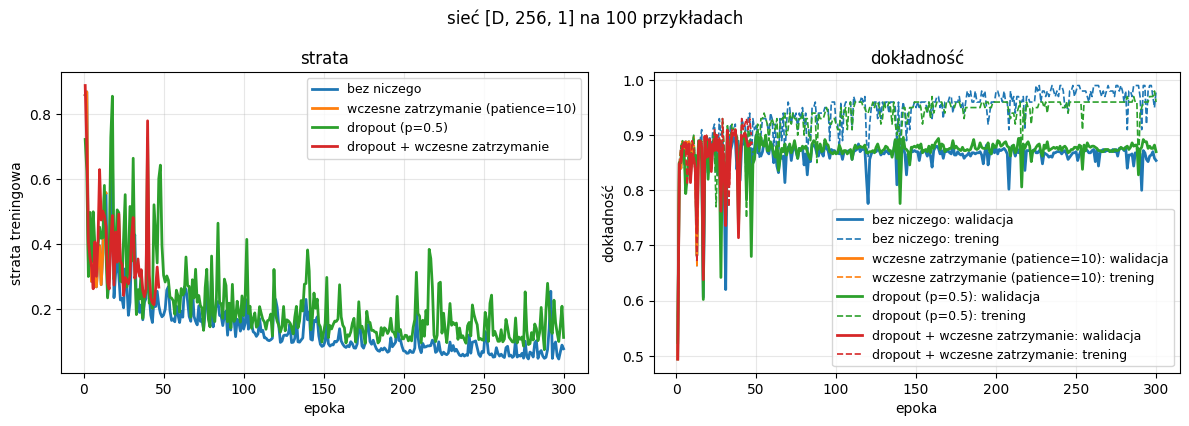

                                    epok  dokł. tren.  dokł. walid.    luka  czas [s]
bez niczego                          300        0.980         0.854   0.126      0.44
wczesne zatrzymanie (patience=10)     14        0.870         0.874  -0.004      0.03
dropout (p=0.5)                      300        0.960         0.870   0.090      0.57
dropout + wczesne zatrzymanie         47        0.900         0.886   0.014      0.07


In [ ]:
runs = {
    "bez niczego": dict(),
    "wczesne zatrzymanie (patience=10)": dict(early_stopping=EarlyStopping(patience=10)),
    "dropout (p=0.5)": dict(forward_fn=forward_dropout, backward_fn=backward_dropout),
    "dropout + wczesne zatrzymanie": dict(
        forward_fn=forward_dropout, backward_fn=backward_dropout, early_stopping=EarlyStopping(patience=10)
    ),
}
histories = {}
for name, kwargs in runs.items():
    params_run = init_params(X_train.shape[1], 256, seed=42)  # te same wagi startowe w każdym wariancie
    histories[name] = train(params_run, X_subset, y_subset, X_val, y_val, lr=LR_SUBSET, epochs=EPOCHS_SUBSET, **kwargs)

plot_history(histories, f"sieć [D, 256, 1] na {len(X_subset)} przykładach")
print_summary(histories)

Wczesne zatrzymanie przerywa po 14 epokach: luki nie ma (0,87 / 0,87), a walidacja to 0,874 zamiast 0,854 po 300 epokach bez niczego. Sam dropout zmniejsza lukę z 0,13 do 0,09 i podnosi walidację do 0,87, ale sieć uczy się wolniej (w każdym kroku połowa neuronów nie pracuje), więc po 300 epokach nadal ma 0,96 na treningu. Dropout razem z wczesnym zatrzymaniem: 47 epok, luka 0,01, walidacja 0,886 — najlepszy wynik, choć przy 500 przykładach walidacyjnych różnice rzędu 0,01 to szum (błąd standardowy ok. 0,014).

| zapis | działanie |
|---|---|
| `es.step(val_acc)` | wywoływane po każdej epoce; `True` oznacza koniec uczenia |
| `rng.random(X.shape) >= p` | maska dropoutu: `True` z prawdopodobieństwem `1 - p` |
| `X * mask / (1 - p)` | wyłączenie i przeskalowanie, żeby oczekiwana wartość aktywacji się nie zmieniła |
| `forward_fn=forward_dropout` | dropout tylko w krokach uczenia; `accuracy` liczy zwykłym `forward` — tryb testowy |

Ani wczesne zatrzymanie, ani dropout nie dodają informacji o danych — ograniczają zapamiętywanie. Zmniejszają lukę,
a dokładność walidacyjną poprawiają tylko o tyle, o ile przeuczenie naprawdę ją psuło. Oba mają hiperparametry
(`patience`, `p`), które — jak każdy hiperparametr — dobiera się na zbiorze walidacyjnym.


### 4.3 Ocena końcowa: zbiór testowy i macierz pomyłek

Na koniec, **raz**, zbiór testowy: sieć `[D, 64, 1]` z punktu 2.4, bez dropoutu, uczona na pełnym zbiorze treningowym
z wczesnym zatrzymaniem (`patience=5` — na 1 500 przykładach krzywa walidacyjna jest spokojniejsza niż na 100, więc
wystarczy krótsza cierpliwość), oceniana na danych, które nie brały udziału w żadnej decyzji. Sama dokładność nie mówi jednak, **jakie** błędy sieć popełnia. Pokazuje to
**macierz pomyłek** (*confusion matrix*): wiersze to prawdziwa klasa, kolumny — klasa przewidziana, a w komórkach liczba
przykładów. Na przekątnej są trafienia (TN, TP), poza nią dwa rodzaje błędów: **fałszywie dodatnie** (FP: sieć wskazała
klasę 1, a była 0) i **fałszywie ujemne** (FN: sieć wskazała 0, a była 1). Z macierzy liczy się precyzję
$\mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$ — jaka część wskazań klasy 1 jest trafna — i czułość $\mathrm{TP}/(\mathrm{TP}+\mathrm{FN})$ —
jaką część przykładów klasy 1 sieć znalazła. Przy zrównoważonych klasach, jak tu, dokładność wystarcza; przy rzadkiej
klasie (np. 1 % przypadków choroby) sieć zwracająca zawsze 0 ma 99 % dokładności i zerową czułość — macierz pomyłek
to pokaże, dokładność nie.


epok: 12   dokładność walidacyjna: 0.896   testowa: 0.876


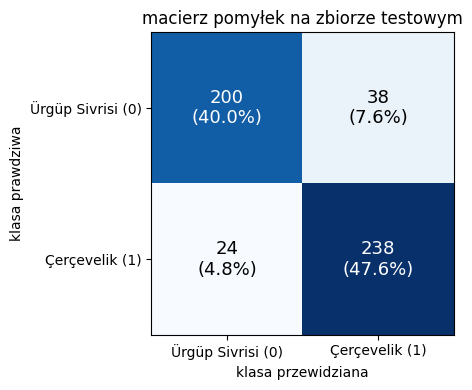

TN = 200, FP = 38, FN = 24, TP = 238
dokładność (TP + TN) / N = 0.876
precyzja TP / (TP + FP) = 0.862   czułość TP / (TP + FN) = 0.908


In [ ]:
def confusion_matrix(params, X, y):
    """Macierz 2 x 2: wiersze = prawdziwa klasa (0, 1), kolumny = klasa przewidziana (0, 1)."""
    z, _ = forward(params, X)
    y_pred = (z > 0).astype(int).ravel()
    y_true = y.astype(int).ravel()
    cm = np.zeros((2, 2), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def plot_confusion_matrix(cm, class_names, title):
    """Rysuje macierz pomyłek z liczbami i udziałami w komórkach."""
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center", fontsize=13, color=color)
    ax.set_xticks([0, 1], class_names)
    ax.set_yticks([0, 1], class_names)
    ax.set_xlabel("klasa przewidziana")
    ax.set_ylabel("klasa prawdziwa")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


params_final = init_params(X_train.shape[1], 64, seed=42)
history_final = train(params_final, X_train, y_train, X_val, y_val, lr=0.05, epochs=100, early_stopping=EarlyStopping(patience=5))
test_acc = accuracy(params_final, X_test, y_test)
print(f"epok: {len(history_final['val_acc'])}   dokładność walidacyjna: {history_final['val_acc'][-1]:.3f}   testowa: {test_acc:.3f}")

cm = confusion_matrix(params_final, X_test, y_test)
(tn, fp), (fn, tp) = cm
plot_confusion_matrix(cm, ["Ürgüp Sivrisi (0)", "Çerçevelik (1)"], "macierz pomyłek na zbiorze testowym")
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
precision, recall = tp / (tp + fp), tp / (tp + fn)
print(f"dokładność (TP + TN) / N = {(tp + tn) / cm.sum():.3f}")
print(f"precyzja TP / (TP + FP) = {precision:.3f}   czułość TP / (TP + FN) = {recall:.3f}")

Na pełnym zbiorze treningowym (1 500 przykładów) wczesne zatrzymanie kończy uczenie po 12 epokach: walidacja 0,896, test 0,876. Wynik testowy jest o 0,02 niższy — zbiór walidacyjny brał udział w decyzji „kiedy przestać”, więc jego ocena jest lekko optymistyczna; dlatego ostatnie słowo należy do zbioru testowego. Macierz pomyłek: 38 ziaren Ürgüp Sivrisi sieć uznała za Çerçevelik (FP), 24 ziarna Çerçevelik za Ürgüp Sivrisi (FN); precyzja 0,86, czułość 0,91 — sieć częściej wskazuje klasę 1 niż powinna, co przy zrównoważonych klasach jest tylko ciekawostką, a przy rzadkiej klasie byłoby istotną informacją.


## Podsumowanie

- Dane dzielimy na trzy zbiory: treningowy (gradient), walidacyjny (pomiar w trakcie, decyzje) i testowy (jedna ocena
  na końcu). Cechy standaryzujemy, żeby wszystkie miały tę samą skalę i pobudzenia były rzędu 1; statystyki liczymy
  tylko na zbiorze treningowym.
- Krok uczenia to trzy funkcje i warstwa straty między nimi: `forward` (zapamiętuje wejścia warstw) → `sigmoid_bce_forward`
  / `sigmoid_bce_backward` → `backward` (te same warstwy od końca, gradient dla każdej tablicy) → `optimizer_step`
  (`params -= lr * grads`). Pętla w praktyce robi te kroki na mini-paczkach, epoka po epoce, i po każdej epoce mierzy
  dokładność walidacyjną.
- Przeuczenie: dokładność treningowa rośnie, walidacyjna staje — luka uogólnienia; niedouczenie: obie niskie. Wczesne
  zatrzymanie kończy uczenie, gdy walidacja przestaje się poprawiać; dropout losowo wyłącza neurony w każdym kroku
  i skaluje resztę przez $1/(1-p)$, a w teście nie działa. Oba ograniczają zapamiętywanie, nie dodają informacji.

**Co dalej.** W Laboratorium 4 te same dane i ta sama sieć w PyTorch: `autograd` zastępuje ręczne `backward`,
`nn.Module` — słownik `params` z funkcją `forward`, `torch.optim` — `optimizer_step`, a `DataLoader` — pętlę po mini-paczkach.

## Do oddania

Wykonany notatnik: wszystkie komórki uruchomione, komórki sprawdzające Zadań 1–3 przechodzą bez błędu. Każde zadanie
to 1 pkt.

## Materiały

- N. Srivastava i in., [*Dropout: A Simple Way to Prevent Neural Networks from Overfitting*](https://jmlr.org/papers/v15/srivastava14a.html), JMLR 2014.
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), MIT Press 2016 — r. 5.2–5.3 (przeuczenie, zbiór walidacyjny), 7.8 (wczesne zatrzymanie), 7.12 (dropout), 8.1.3 (mini-paczki).
- CS231n, [*Neural Networks Part 2: Setting up the Data and the Loss*](https://cs231n.github.io/neural-networks-2/) (standaryzacja, dropout).
- M. Koklu, S. Sarigil, O. Özbek, [*The use of machine learning methods in classification of pumpkin seeds (Cucurbita pepo L.)*](https://doi.org/10.1007/s10722-021-01226-0), Genetic Resources and Crop Evolution 68, 2021, s. 2713–2726; zbiór: [strona autora](https://www.muratkoklu.com/datasets/), kopia w repozytorium kursu (`data/pumpkin_seeds.csv`).
